# Fotoğraf dokusundan tane boyutu tahmini
Bu deney yalnızca eğitim numunelerini kullanır. Her turda bir numuneyi saklayıp fotoğraflarına en çok benzeyen üç numunenin laboratuvar eğrilerinin ortalamasını hesaplarız.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
from sklearn.preprocessing import StandardScaler

root = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path("work/soil-data")
data = next(root.rglob("Training_labels_updated.csv")).parent
labels = pd.read_csv(data / "Training_labels_updated.csv").set_index("sample_id")
cameras = pd.read_csv(data / "ppm_updated.csv")
photos = sorted(data.joinpath("Training-All_Photos_updated").rglob("*.jpg"))
print(f"{len(labels)} numune, {len(photos)} eğitim fotoğrafı")

24 numune, 127 eğitim fotoğrafı


## 1. Fotoğrafı bir avuç sayıyla anlatmak
Bütün fotoğrafların merkezinden yaklaşık 100 × 100 mm alan alıyoruz. Kamera tablosundaki piksel/mm değerini gerçek dosyanın çözünürlüğüne uyarlıyoruz. Bu kalibrasyon, çekim uzaklığının kamera tablosunda varsayılana yakın olduğunu kabul eder.

Bu alanı griye çevirip 400 × 400 piksele getiriyoruz. Yatay ve dikey yönde, birbirinden 0,25 mm ile 8 mm arasında uzakta olan noktaların ne kadar farklı aydınlıkta göründüğünü ölçüyoruz. Böylece her fotoğrafta aynı altı fiziksel uzaklığı karşılaştırıyoruz. Her numunenin fotoğraflarını, her ölçünün ortanca değerini alarak birleştiriyoruz.

In [2]:
def physical_patch(path, camera):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image)
        w, h = image.size
        pixels_per_mm = camera.ppm * max(w, h) / max(camera.width, camera.height)
        side = round(100 * pixels_per_mm)
        assert 0 < side <= min(w, h)
        x, y = (w - side) // 2, (h - side) // 2
        return image.crop((x, y, x + side, y + side)).convert("RGB").resize((400, 400), Image.Resampling.LANCZOS)

def texture(patch):
    gray = np.asarray(patch.convert("L"), dtype=float)
    low, high = np.percentile(gray, [5, 95])
    gray = np.clip((gray - low) / max(high - low, 1.0), 0, 1)
    values = []
    for offset in [1, 2, 4, 8, 16, 32]:
        horizontal = np.abs(gray[:, offset:] - gray[:, :-offset]).mean()
        vertical = np.abs(gray[offset:, :] - gray[:-offset, :]).mean()
        values.append((horizontal + vertical) / 2)
    return values

camera_by_name = {c.phone.replace(" ", "_").lower(): c for c in cameras.itertuples()}
rows = []
examples = {}
for path in photos:
    phone, sample, number = path.stem.rsplit("_", 2)
    patch = physical_patch(path, camera_by_name[phone.lower()])
    rows.append([sample, *texture(patch)])
    examples.setdefault(sample, patch)
features = pd.DataFrame(rows, columns=["sample_id", "0.25", "0.5", "1", "2", "4", "8"])
features = features.groupby("sample_id").median()
assert set(features.index) == set(labels.index)
features = features.loc[labels.index]

## 2. Gerçek cevabı saklayıp tahmin yapmak
Her turda yalnızca geride kalan 23 numuneden ölçekleme değerlerini öğreniyoruz. Altı doku ölçüsüne göre uzaklık hesaplayıp en yakın üç komşuyu seçiyoruz. Komşuların ölçümlerinin ortalaması tahminimiz oluyor. Karşılaştırma için aynı 23 numunenin tamamının ortalamasını da hesaplıyoruz.

In [3]:
sizes = labels.columns.astype(float).to_numpy()
widths = np.diff(np.log10(sizes))

def emd(observed, predicted):
    return np.abs(observed[:-1] - predicted[:-1]) @ widths

scores, neighbors, predictions, averages = [], {}, {}, {}
for sample in labels.index:
    train = features.drop(index=sample)
    scaler = StandardScaler().fit(train)
    distance = np.linalg.norm(scaler.transform(train) - scaler.transform(features.loc[[sample]]), axis=1)
    nearest = train.index[np.argsort(distance, kind="stable")[:3]].tolist()
    predicted = labels.loc[nearest].mean().to_numpy()
    baseline = labels.loc[train.index].mean().to_numpy()
    observed = labels.loc[sample].to_numpy()
    assert sample not in nearest and len(set(nearest)) == 3
    assert np.all(np.diff(predicted) >= -1e-10) and np.isclose(predicted[-1], 100)
    scores.append((sample, emd(observed, baseline), emd(observed, predicted)))
    neighbors[sample], predictions[sample], averages[sample] = nearest, predicted, baseline
scores = pd.DataFrame(scores, columns=["Numune", "Ortalama", "Üç komşu"]).set_index("Numune")
print(scores.mean().round(2).to_string())
print(f"Üç komşunun daha az hata yaptığı numune sayısı: {(scores['Üç komşu'] < scores['Ortalama']).sum()}/{len(scores)}")

Ortalama    89.89
Üç komşu    44.74
Üç komşunun daha az hata yaptığı numune sayısı: 18/24


## 3. F827 için modelin seçtiği komşular
İlk derste gördüğümüz ince toprak F827'yi seçiyoruz. Üst sırada solda onun fotoğrafından bir kesit, yanında modelin seçtiği üç komşu var. Altta üç eğriyi karşılaştırabilirsin: kesikli gri çizgi başlangıç tahmini, turuncu çizgi fotoğraflardan tahmin, yeşil çizgi ise laboratuvar ölçümü.

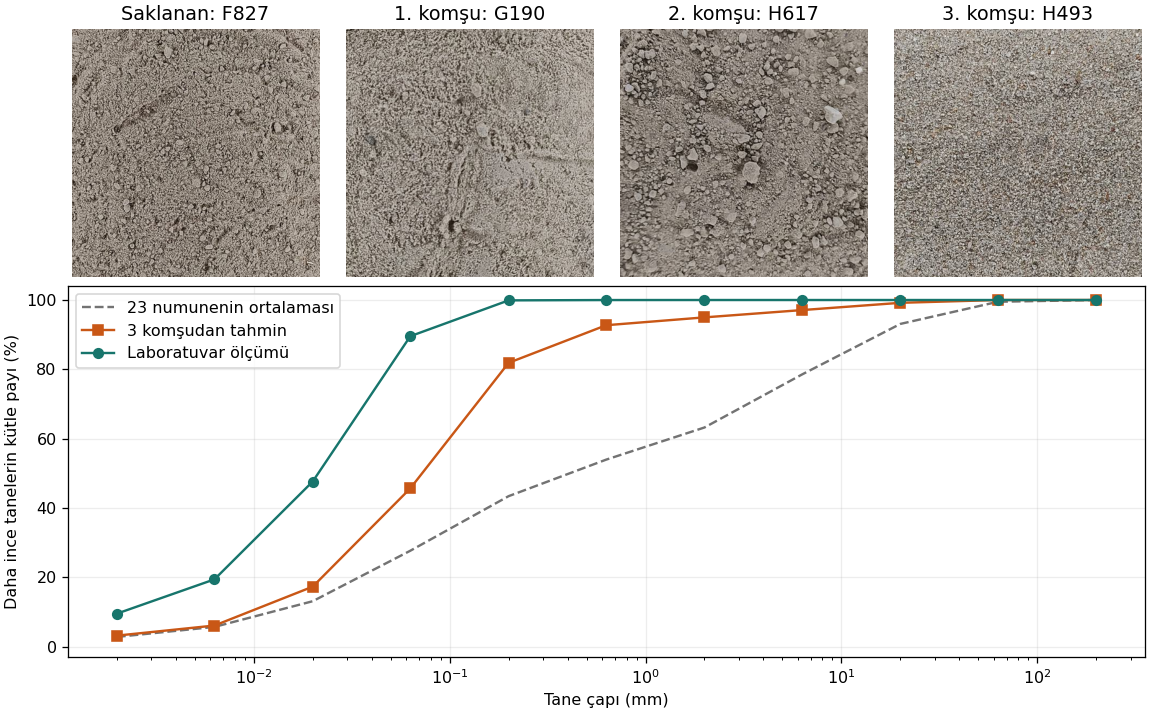

In [4]:
sample = "F827"
fig = plt.figure(figsize=(10, 6.2), layout="constrained")
grid = fig.add_gridspec(2, 4, height_ratios=[1, 1.5])
for i, name in enumerate([sample, *neighbors[sample]]):
    ax = fig.add_subplot(grid[0, i])
    ax.imshow(examples[name])
    ax.set_title(f"Saklanan: {name}" if i == 0 else f"{i}. komşu: {name}")
    ax.set_axis_off()
ax = fig.add_subplot(grid[1, :])
ax.semilogx(sizes, averages[sample], "--", color="#737373", label="23 numunenin ortalaması")
ax.semilogx(sizes, predictions[sample], "s-", color="#c95716", label="3 komşudan tahmin")
ax.semilogx(sizes, labels.loc[sample], "o-", color="#17756c", label="Laboratuvar ölçümü")
ax.set(xlabel="Tane çapı (mm)", ylabel="Daha ince tanelerin kütle payı (%)", ylim=(-3, 104))
ax.legend()
ax.grid(alpha=0.22)
plt.show()